# 1. General settings

In [1]:
import pygmt
import pandas as pd
pygmt.show_versions()

PyGMT information:
  version: v0.13.0
System information:
  python: 3.10.21 | packaged by conda-forge | (main, Aug 21 2026, 22:37:53) [Clang 19.1.7 ]
  executable: /Users/dfbarbag/Documents/Projects/00_CE746_Workshops/3_OpenQuake/.venv/bin/python
  machine: macOS-26.7.1-arm64-arm-64bit
Dependency information:
  numpy: 1.26.4
  pandas: 2.3.3
  xarray: 2025.6.1
  netCDF4: 1.7.2
  packaging: 26.3
  contextily: None
  geopandas: 1.1.4
  IPython: 8.37.0
  rioxarray: None
  gdal: 3.10.3
  ghostscript: 10.08.0
GMT library information:
  version: 6.6.0
  padding: 2
  share dir: /Users/dfbarbag/Documents/Projects/00_CE746_Workshops/3_OpenQuake/.venv/share/gmt
  plugin dir: /Users/dfbarbag/Documents/Projects/00_CE746_Workshops/3_OpenQuake/.venv/lib/gmt/plugins
  library path: /Users/dfbarbag/Documents/Projects/00_CE746_Workshops/3_OpenQuake/.venv/lib/libgmt.dylib
  cores: 10
  grid layout: rows
  image layout: 
  binary version: 6.6.0


# 2. Read data

In [2]:
event = pd.read_csv("data/Niigata_event.csv")
event.head()

,event_name,longitude,latitude,depth,strike,dip,rake,magnitude,plot_longitude,plot_latitude
0,Mw6.6 Niigata,138.779,37.226,16,220,55,90,6.6,138,39


In [3]:
df_NGAW2 = pd.read_excel("data/Updated_NGA_West2_Flatfile_RotD50_d005_public_version.xlsx")
print(df_NGAW2.head())

/Users/dfbarbag/Documents/Projects/00_CE746_Workshops/3_OpenQuake/.venv/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


   Record Sequence Number  EQID     Earthquake Name  YEAR  MODY  HRMN  \
0                       1     1  Helena, Montana-01  1935  1031  1838   
1                       2     2  Helena, Montana-02  1935  1031  1918   
2                       3     3         Humbolt Bay  1937   207   442   
3                       4     4  Imperial Valley-01  1938   606   242   
4                       5     5  Northwest Calif-01  1938   912   610   

         Station Name  Station Sequence Number Station ID  No.  \
0     Carroll College                      197            2022   
1     Helena Fed Bldg                      198            2229   
2  Ferndale City Hall                      133            1023   
3  El Centro Array #9                       75             117   
4  Ferndale City Hall                      133            1023   

   Earthquake Magnitude  ... Instrument Nat. Freq.  Instrument Damping  \
0                   6.0  ...                -999.0              -999.0   
1               

In [4]:
import json
import geopandas as gpd
import io

# Reading as a GeoDataFrame to visualize the rupture geometry
rupture = gpd.read_file("data/niigata_rupture.json")

# Exploring the rupture geometry
with open('data/niigata_rupture.json', 'r') as file:
    rupture_json = json.load(file)

rupture_json

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'geometry': {'type': 'MultiPolygon',
    'coordinates': [[[[139.02, 37.38, 5.0],
       [138.87, 37.19, 5.0],
       [138.8, 37.22, 15.0],
       [138.95, 37.42, 15.0],
       [139.02, 37.38, 5.0]]]]},
   'properties': {'rupture type': 'rupture extent'}}],
 'metadata': {'depth': 16.0,
  'lon': 138.779,
  'netid': 'us',
  'mag': 6.6,
  'id': 'usp000d6vk',
  'lat': 37.226,
  'rake': 0.0,
  'time': '2004-10-23T08:56:00.000000Z',
  'mech': 'ALL',
  'locstring': 'near the west coast of Honshu, Japan',
  'network': 'USGS National Earthquake Information Center, PDE',
  'reference': 'Joshi, A., and K. Mohan (2008). Simulation of accelerograms from simplified deterministic approach for the 23rd October 2004 Niigata-ken Chuetsu, Japan earthquake. J. Seismology 12, 1, 35-51.',
  'productcode': 'usp000d6vk'}}

# 3. Selecting the stations and general plot

In [5]:
df_niigata = df_NGAW2[df_NGAW2['Earthquake Name']=="Niigata, Japan"]
print("Number of stations:", len(df_niigata))
df_niigata.head()

Number of stations: 530


,Record Sequence Number,EQID,Earthquake Name,YEAR,MODY,HRMN,Station Name,Station Sequence Number,Station ID No.,Earthquake Magnitude,...,Instrument Nat. Freq.,Instrument Damping,Instrument Type,Quality_Flag,Spectra Quality Flag,Late S-trigger,Late P-trigger,Idirectivity,Tp,Ry 2
4150,4151,180,"Niigata, Japan",2004,1023,856,FKS020,1859,FKS020,6.63,...,-999.0,-999.0,-999,-999,0,-999,-999,0,-999.0,-81.642555
4151,4152,180,"Niigata, Japan",2004,1023,856,FKS021,1860,FKS021,6.63,...,-999.0,-999.0,-999,-999,0,-999,-999,0,-999.0,-79.933846
4152,4153,180,"Niigata, Japan",2004,1023,856,FKS022,1861,FKS022,6.63,...,-999.0,-999.0,-999,-999,0,-999,-999,0,-999.0,-64.661208
4153,4154,180,"Niigata, Japan",2004,1023,856,FKS023,1862,FKS023,6.63,...,-999.0,-999.0,-999,-999,0,-999,-999,0,-999.0,-66.576311
4154,4155,180,"Niigata, Japan",2004,1023,856,FKS024,1863,FKS024,6.63,...,-999.0,-999.0,-999,-999,0,-999,-999,0,-999.0,-68.628361


makecpt [WARNING]: Without inc in -T option, -Z has no effect (ignored)


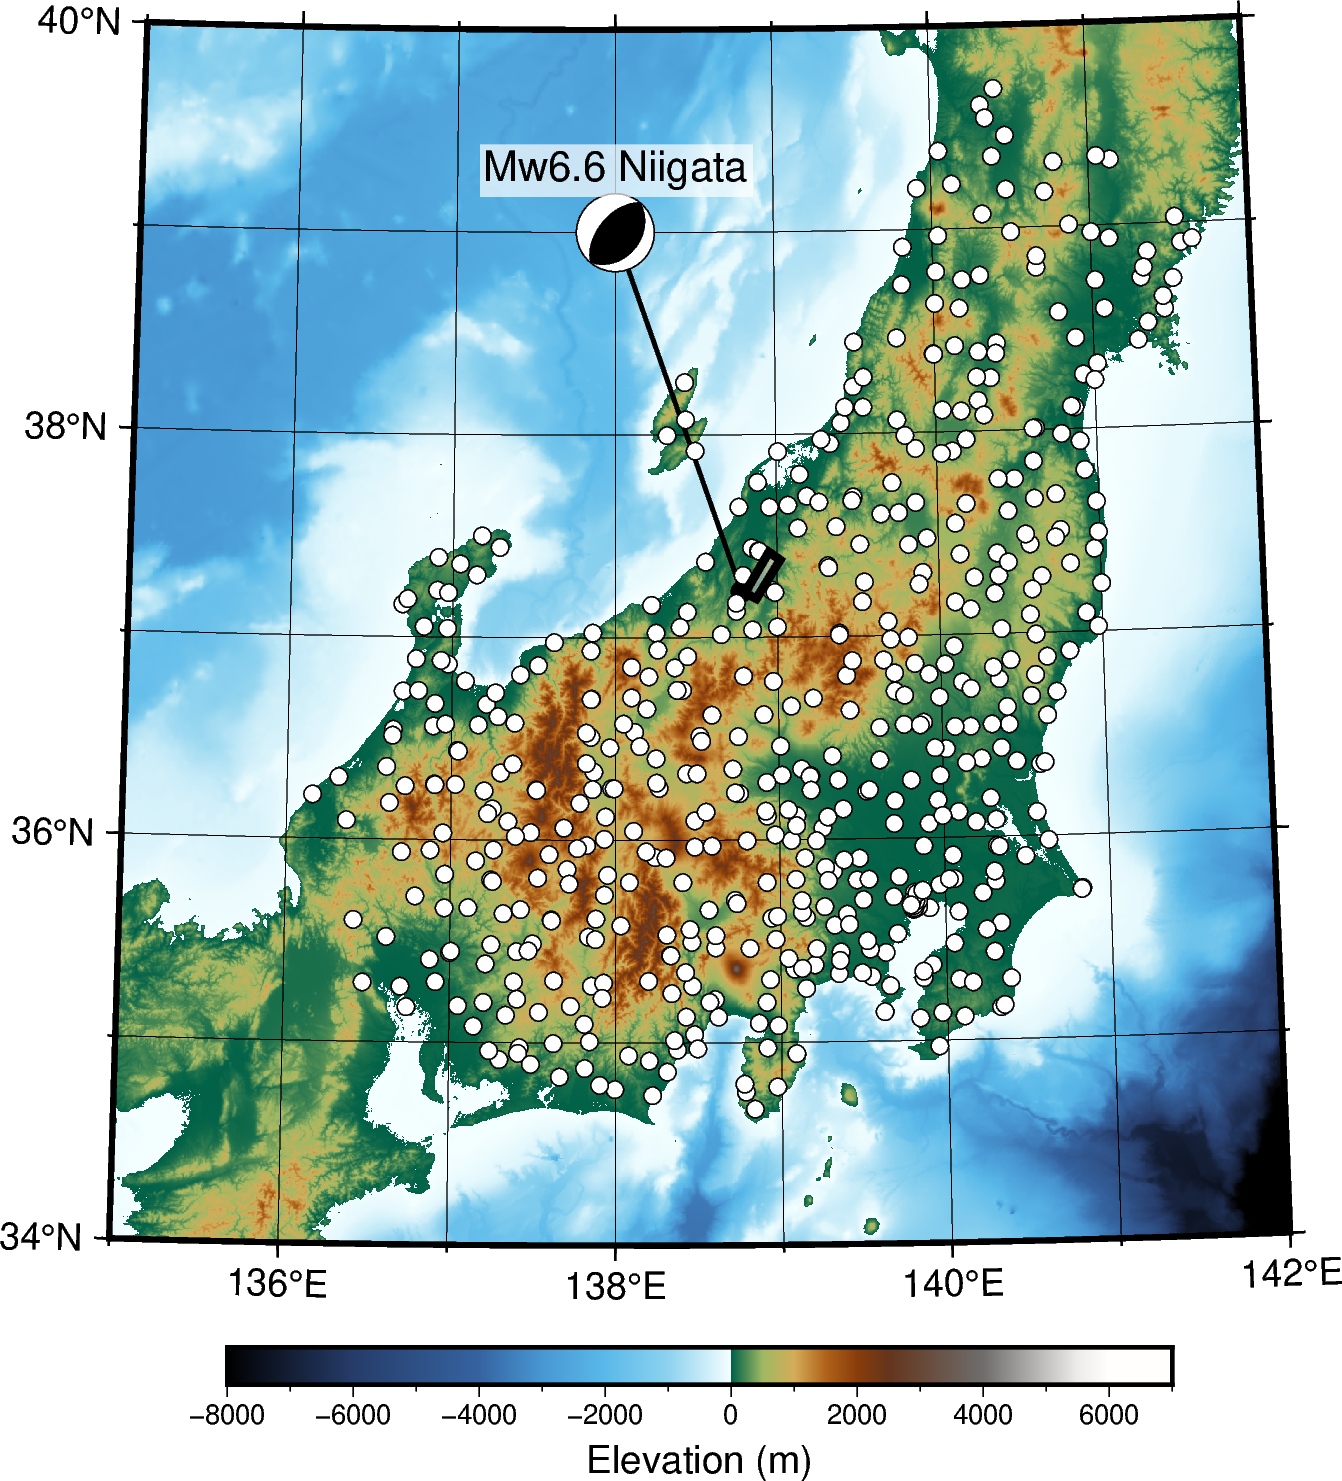

In [6]:
fig = pygmt.Figure()
region = [135, 142, 34, 40]
proj = "T138/38/10c"

grid = pygmt.datasets.load_earth_relief(resolution="15s", region=region)
pygmt.makecpt(cmap="geo", series=[-8000, 7000, 500], continuous=True, output="data/eleva.cpt")

fig.grdimage(grid=grid, region=region, projection=proj, cmap="data/eleva.cpt")

with pygmt.config(MAP_GRID_PEN="0.1p,black"):
    fig.basemap(frame=["WSne", "a2f1g1"])

fig.meca(spec=event.iloc[0,0:].to_dict(), scale="0.5c+f10p", labelbox="white@30", offset="+p1p,black+s0.15c")

vmin = df_niigata['Vs30 (m/s) selected for analysis'].quantile(0.1)
vmax = df_niigata['Vs30 (m/s) selected for analysis'].quantile(0.9)
pygmt.makecpt(
    cmap="wysiwyg", series=[vmin, vmax],
    continuous=True, background = True, output="data/station.cpt"
)

fig.plot(x=df_niigata["Station Longitude"], y=df_niigata["Station Latitude"], fill="white", style="c0.15c", pen="black")

fig.plot(
                data=rupture,
                pen="2p,black", 
                fill = "grey@40"
        )

fig.colorbar(cmap="data/eleva.cpt",
    frame="a2000f1000+lElevation (m)"
)

fig.show()

# 4. Distance metrics

In [7]:
import numpy as np
from openquake.hazardlib.geo import Point, Mesh
from openquake.hazardlib.geo.mesh import RectangularMesh
from openquake.hazardlib.geo.surface import PlanarSurface, SimpleFaultSurface


In [8]:
# Reading points
df_stations = pd.DataFrame()
df_stations['station'] = df_niigata['Station Name'].values
df_stations['lon'] = df_niigata['Station Longitude'].values
df_stations['lat'] = df_niigata['Station Latitude'].values
depth_site = np.zeros_like(df_stations['lon'] , dtype=float)

site_mesh = Mesh(
    np.array(df_stations['lon'].values), 
    np.array(df_stations['lat'].values), 
    np.array(depth_site)
)

In [9]:
lon_epi = event['longitude'].values
lat_epi = event['latitude'].values
depth_epi = event['depth'].values
eq_point = Point(lon_epi, lat_epi, depth_epi)

In [10]:
df_stations['r_epi'] = eq_point.distance_to_mesh(site_mesh, with_depths=False)
df_stations['r_hypo'] = eq_point.distance_to_mesh(site_mesh, with_depths=True)
df_stations.head()

,station,lon,lat,r_epi,r_hypo
0,FKS020,140.1078,37.5474,122.717931,123.756578
1,FKS021,139.8633,37.6535,106.882176,108.073121
2,FKS022,139.6467,37.6002,87.201547,88.657260
3,FKS023,139.9294,37.4774,105.457564,106.664416
4,FKS024,140.1325,37.3957,121.180382,122.232095


In [11]:

polygon_coordinates = rupture_json['features'][0]['geometry']['coordinates'][0][0]

points = []
for lon, lat, depth in polygon_coordinates[:-1]:  # Exclude last point because it close the polygon
    points.append(Point(lon, lat, depth))
rupture_surface = PlanarSurface.from_corner_points(points[0], points[1], points[2], points[3])

In [12]:
# Rrup, Rjb, and Rx distances
df_stations['r_rup'] = rupture_surface.get_min_distance(site_mesh)
df_stations['r_jb'] = rupture_surface.get_joyner_boore_distance(site_mesh)
df_stations['rx'] = rupture_surface.get_rx_distance(site_mesh)
#Ztor 
df_stations['Ztor'] = rupture_surface.get_top_edge_depth()
df_stations

,station,lon,lat,r_epi,r_hypo,r_rup,r_jb,rx,Ztor
0,FKS020,140.1078,37.5474,122.717931,123.756578,97.884547,97.795144,-70.958107,5.0
1,FKS021,139.8633,37.6535,106.882176,108.073121,80.476934,80.352997,-46.460470,5.0
2,FKS022,139.6467,37.6002,87.201547,88.657260,60.653939,60.471234,-33.591268,5.0
3,FKS023,139.9294,37.4774,105.457564,106.664416,81.149530,81.027148,-61.945302,5.0
4,FKS024,140.1325,37.3957,121.180382,122.232095,98.390982,98.302437,-81.939728,5.0
...,...,...,...,...,...,...,...,...,...
525,YMTH09,140.1814,38.7469,209.053024,209.664415,182.851917,182.704918,-3.972052,5.0
526,YMTH12,140.0089,38.6328,190.011477,190.683931,164.055796,164.039417,1.725922,5.0
527,YMTH13,139.7639,38.4675,162.896409,163.680298,137.399551,136.599672,9.719173,5.0
528,YMTH14,139.9950,38.3831,167.231293,167.994956,140.610866,140.577114,-12.291477,5.0


# 5. Site parameters and observations

In [13]:
# Site parameters
df_stations['Vs30'] = df_niigata['Vs30 (m/s) selected for analysis'].values
df_stations['Z1'] = df_niigata['Northern CA/Southern CA - H11 Z1 (m)'].values
df_stations

,station,lon,lat,r_epi,r_hypo,r_rup,r_jb,rx,Ztor,Vs30,Z1
0,FKS020,140.1078,37.5474,122.717931,123.756578,97.884547,97.795144,-70.958107,5.0,133.05,360.0
1,FKS021,139.8633,37.6535,106.882176,108.073121,80.476934,80.352997,-46.460470,5.0,370.40,220.0
2,FKS022,139.6467,37.6002,87.201547,88.657260,60.653939,60.471234,-33.591268,5.0,211.76,200.0
3,FKS023,139.9294,37.4774,105.457564,106.664416,81.149530,81.027148,-61.945302,5.0,182.30,300.0
4,FKS024,140.1325,37.3957,121.180382,122.232095,98.390982,98.302437,-81.939728,5.0,234.27,120.0
...,...,...,...,...,...,...,...,...,...,...,...
525,YMTH09,140.1814,38.7469,209.053024,209.664415,182.851917,182.704918,-3.972052,5.0,291.48,44.0
526,YMTH12,140.0089,38.6328,190.011477,190.683931,164.055796,164.039417,1.725922,5.0,366.93,20.0
527,YMTH13,139.7639,38.4675,162.896409,163.680298,137.399551,136.599672,9.719173,5.0,576.97,40.0
528,YMTH14,139.9950,38.3831,167.231293,167.994956,140.610866,140.577114,-12.291477,5.0,310.88,40.0


In [14]:
cols_name = ["Station Name","PGA (g)"]
observed_data = df_niigata[cols_name].reset_index(drop=True)
# Renaming the columns
observed_data.columns = ['station'] + ['PGA']
observed_data.head()

,station,PGA
0,FKS020,0.043384
1,FKS021,0.122900
2,FKS022,0.143550
3,FKS023,0.057119
4,FKS024,0.049540


In [16]:
merged_df = pd.merge(
    df_stations[['station', 'r_hypo', 'r_jb', 'Vs30']],            
    observed_data[['station', 'PGA']],          
    on='station',                        # Common column to match on
    how='inner'                          
)

merged_df.head()

,station,r_hypo,r_jb,Vs30,PGA
0,FKS020,123.756578,97.795144,133.05,0.043384
1,FKS021,108.073121,80.352997,370.40,0.122900
2,FKS022,88.657260,60.471234,211.76,0.143550
3,FKS023,106.664416,81.027148,182.30,0.057119
4,FKS024,122.232095,98.302437,234.27,0.049540


/var/folders/vc/yzs66q6s725d0myb9d9c6jhw0000gq/T/ipykernel_62841/1699783079.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for category, group in merged_df.groupby('soil_category'):
/var/folders/vc/yzs66q6s725d0myb9d9c6jhw0000gq/T/ipykernel_62841/1699783079.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for category, group in merged_df.groupby('soil_category'):


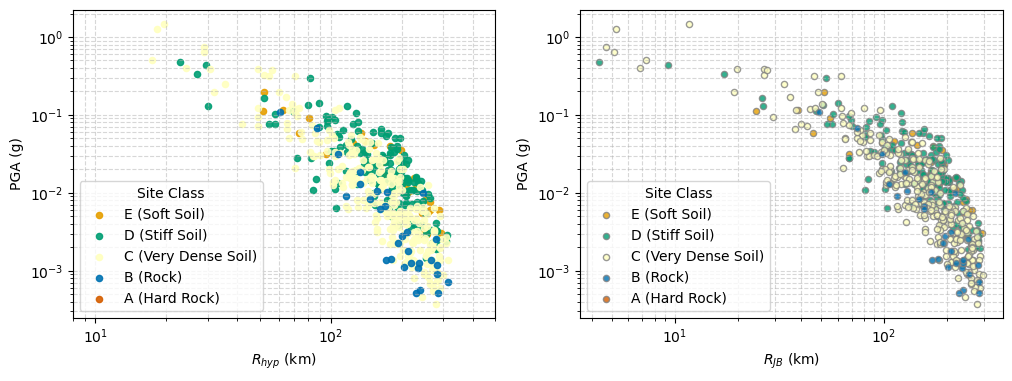

In [42]:
import matplotlib.pyplot as plt

bins = [0, 180, 360, 760, 1500, np.inf]
labels = ['E (Soft Soil)', 'D (Stiff Soil)', 'C (Very Dense Soil)', 'B (Rock)', 'A (Hard Rock)']
merged_df['soil_category'] = pd.cut(merged_df['Vs30'], bins=bins, labels=labels)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
colors = {'E (Soft Soil)': '#E69F00', 'D (Stiff Soil)': '#009E73', 'C (Very Dense Soil)': '#ffffbf', 'B (Rock)': '#0072B2', 'A (Hard Rock)': '#D55E00'}

# Rhypo
for category, group in merged_df.groupby('soil_category'):
    ax[0].scatter(
        group['r_hypo'], 
        group['PGA'], 
        label=category,                         
        color=colors.get(category, 'gray'),     
        marker='o',    
        s=20, 
        alpha=0.9
    )

ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel(r'$R_{hyp}$ (km)')
ax[0].set_xlim([8,500])
ax[0].set_ylabel('PGA (g)')
ax[0].grid(True, which="both", ls="--", alpha=0.5)
ax[0].legend(title="Site Class", loc="lower left")

# R_JB
for category, group in merged_df.groupby('soil_category'):
    ax[1].scatter(
        group['r_jb'], 
        group['PGA'], 
        label=category,                         
        color=colors.get(category, 'gray'),     
        marker='o',    
        s=20, 
        edgecolors = 'gray',
        alpha=0.8
    )

ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_xlabel(r'$R_{JB}$ (km)')
ax[0].set_xlim([8,500])
ax[1].set_ylabel('PGA (g)')
ax[1].grid(True, which="both", ls="--", alpha=0.5)
ax[1].legend(title="Site Class", loc="lower left")

plt.show()

# 6. Residuals

# 

In [43]:
from openquake.hazardlib import gsim
from openquake.hazardlib.gsim.boore_2014 import BooreEtAl2014
from openquake.hazardlib.imt import PGA, PGV, SA
from openquake.hazardlib.contexts import simple_cmaker

In [44]:
# GMM
gsim = BooreEtAl2014()

# Define IMTs 
imts = [PGA(), PGV()]

periods = [0.02,0.04,0.08,0.1,0.2,0.4,0.8,1,2,3]
for T in periods:
    imts.append(SA(T))
imt_strings = [str(imt) for imt in imts]
print(imt_strings)

['PGA', 'PGV', 'SA(0.02)', 'SA(0.04)', 'SA(0.08)', 'SA(0.1)', 'SA(0.2)', 'SA(0.4)', 'SA(0.8)', 'SA(1.0)', 'SA(2.0)', 'SA(3.0)']


In [46]:
n = len(df_stations)
mag = np.full(n,event['magnitude'][0])

# Setup Context Maker for ALL IMTs
cmaker = simple_cmaker(
    [gsim], imt_strings, mags=["%2.2f" % m for m in mag]
)

ctx = cmaker.new_ctx(n)
# Source parameters
ctx["mag"] = mag 
ctx["rake"] = np.full(n, event['rake'][0])
# Path parameters
ctx["rjb"] = df_stations['r_jb']
# Site parameters
ctx["vs30"] = df_stations['Vs30']
print(ctx[:10])

[(6.6, 90., 133.05, 97.79514438, 0., 0, 0, 0, 0.)
 (6.6, 90., 370.4 , 80.35299684, 0., 0, 0, 0, 0.)
 (6.6, 90., 211.76, 60.47123432, 0., 0, 0, 0, 0.)
 (6.6, 90., 182.3 , 81.02714828, 0., 0, 0, 0, 0.)
 (6.6, 90., 234.27, 98.302437  , 0., 0, 0, 0, 0.)
 (6.6, 90., 615.23, 78.20641863, 0., 0, 0, 0, 0.)
 (6.6, 90., 330.61, 47.57708202, 0., 0, 0, 0, 0.)
 (6.6, 90., 697.72, 67.90643332, 0., 0, 0, 0, 0.)
 (6.6, 90., 305.54, 26.24394619, 0., 0, 0, 0, 0.)
 (6.6, 90., 431.98, 48.58985294, 0., 0, 0, 0, 0.)]


In [47]:
# Run OpenQuake calculation
means, sigmas, taus, phis = cmaker.get_mean_stds([ctx])

In [48]:
# Extract results for each IMT
predicted_data = []

for imt_idx, imt_str in enumerate(imt_strings):
    # Extract arrays for the first GSIM (index 0) and current IMT
    mean_val = means[0][imt_idx]
    sigma_tot = sigmas[0][imt_idx]
    tau = taus[0][imt_idx]
    phi = phis[0][imt_idx]
    
    # Store results row-by-row or append to a structural dataframe
    df_imt = pd.DataFrame({
        'station': df_stations['station'],
        'rjb': df_stations['r_jb'],
        'Vs30': df_stations['Vs30'],
        'imt': imt_str,
        'mean_log': mean_val,
        'sigma': sigma_tot,
        'tau': tau,
        'phi': phi
    })
    predicted_data.append(df_imt)

# Combine all IMT data into a single DataFrame
df_BSSA14 = pd.concat(predicted_data, ignore_index=True)
print(df_BSSA14.head())

  station        rjb    Vs30  imt  mean_log     sigma    tau       phi
0  FKS020  97.795144  133.05  PGA -2.958235  0.549299  0.348  0.425000
1  FKS021  80.352997  370.40  PGA -3.182036  0.605086  0.348  0.495000
2  FKS022  60.471234  211.76  PGA -2.587251  0.549299  0.348  0.425000
3  FKS023  81.027148  182.30  PGA -2.860719  0.549299  0.348  0.425000
4  FKS024  98.302437  234.27  PGA -3.233911  0.556934  0.348  0.434824


In [49]:
cols_name = ["Station Name","PGA (g)", "PGV (cm/sec)", "T0.020S","T0.040S","T0.080S","T0.100S","T0.200S","T0.400S","T0.800S","T1.000S","T2.000S","T3.000S"]
observed_data = df_niigata[cols_name].reset_index(drop=True)
# Renaming the columns
observed_data.columns = ['station'] + np.unique(df_BSSA14['imt']).tolist()
observed_data.head()

,station,PGA,PGV,SA(0.02),SA(0.04),SA(0.08),SA(0.1),SA(0.2),SA(0.4),SA(0.8),SA(1.0),SA(2.0),SA(3.0)
0,FKS020,0.043384,5.7509,0.043705,0.045252,0.057313,0.106166,0.236727,0.133621,0.238585,0.153882,0.125629,0.038112
1,FKS021,0.122900,5.3760,0.123676,0.136088,0.356760,0.455156,0.568531,0.193147,0.127608,0.061806,0.049898,0.019412
2,FKS022,0.143550,7.7938,0.145903,0.192044,0.479134,0.658632,0.349045,1.000016,0.173644,0.108867,0.049133,0.025303
3,FKS023,0.057119,4.5286,0.057304,0.059907,0.111233,0.127660,0.190534,0.360709,0.073670,0.065336,0.049078,0.025774
4,FKS024,0.049540,4.4033,0.049651,0.057002,0.142130,0.350776,0.162596,0.206924,0.098993,0.174195,0.025539,0.008656


In [50]:
observed_data = observed_data.replace(-999, np.nan)
print(observed_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   station   530 non-null    object 
 1   PGA       530 non-null    float64
 2   PGV       530 non-null    float64
 3   SA(0.02)  530 non-null    float64
 4   SA(0.04)  530 non-null    float64
 5   SA(0.08)  530 non-null    float64
 6   SA(0.1)   530 non-null    float64
 7   SA(0.2)   530 non-null    float64
 8   SA(0.4)   530 non-null    float64
 9   SA(0.8)   530 non-null    float64
 10  SA(1.0)   530 non-null    float64
 11  SA(2.0)   530 non-null    float64
 12  SA(3.0)   530 non-null    float64
dtypes: float64(12), object(1)
memory usage: 54.0+ KB
None


In [51]:
# Melt data in format
obs_df = observed_data.melt(
    id_vars=['station'], 
    var_name='imt', 
    value_name='obs'
)
obs_df

,station,imt,obs
0,FKS020,PGA,0.043384
1,FKS021,PGA,0.122900
2,FKS022,PGA,0.143550
3,FKS023,PGA,0.057119
4,FKS024,PGA,0.049540
...,...,...,...
6355,YMTH09,SA(3.0),0.003609
6356,YMTH12,SA(3.0),0.006676
6357,YMTH13,SA(3.0),0.002399
6358,YMTH14,SA(3.0),0.006570


In [52]:
df_BSSA14['obs_log'] = np.log(obs_df['obs'])


# Remove NaN
df_BSSA14 = df_BSSA14.dropna().copy().reset_index(drop=True)

In [53]:
BSSA14 = df_BSSA14[
    (df_BSSA14['rjb']<=400) &
    (df_BSSA14['Vs30'] >= 150) & 
    (df_BSSA14['Vs30'] <= 1500)
    ].copy().reset_index(drop=True)

In [54]:
BSSA14['res_tot'] = BSSA14['obs_log'] - BSSA14['mean_log']
BSSA14.head()

,station,rjb,Vs30,imt,mean_log,sigma,tau,phi,obs_log,res_tot
0,FKS021,80.352997,370.40,PGA,-3.182036,0.605086,0.348,0.495000,-2.096384,1.085652
1,FKS022,60.471234,211.76,PGA,-2.587251,0.549299,0.348,0.425000,-1.941072,0.646179
2,FKS023,81.027148,182.30,PGA,-2.860719,0.549299,0.348,0.425000,-2.862618,-0.001900
3,FKS024,98.302437,234.27,PGA,-3.233911,0.556934,0.348,0.434824,-3.004975,0.228936
4,FKS025,78.206419,615.23,PGA,-3.421444,0.605086,0.348,0.495000,-2.906093,0.515351


In [55]:
# Statistics for each IM
stats_BSSA14 = BSSA14.groupby('imt')['res_tot'].agg(['count','mean','std','min','max']).reset_index()
print(stats_BSSA14)

         imt  count      mean       std       min       max
0        PGA    507 -0.148726  0.717769 -2.097140  1.795126
1        PGV    507 -0.339865  0.545584 -1.670336  1.154937
2   SA(0.02)    507 -0.109003  0.721776 -2.072039  1.813063
3   SA(0.04)    507  0.117090  0.773605 -1.942521  2.867773
4   SA(0.08)    507  0.653408  0.891363 -1.414267  3.258994
5    SA(0.1)    507  0.709464  0.929728 -1.480311  3.529953
6    SA(0.2)    507  0.369102  0.853139 -1.790618  2.643888
7    SA(0.4)    507 -0.046016  0.781273 -2.099340  2.657773
8    SA(0.8)    507 -0.166761  0.755455 -2.269736  2.065429
9    SA(1.0)    507 -0.092284  0.779374 -2.138945  2.070954
10   SA(2.0)    507  0.189272  0.765446 -1.737802  2.898265
11   SA(3.0)    507  0.261855  0.742923 -1.265078  2.576777


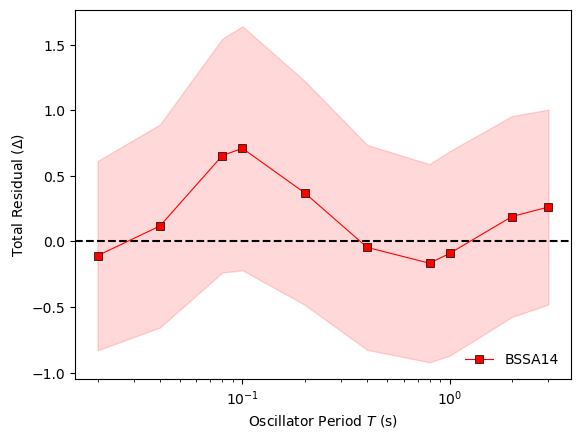

In [56]:
import matplotlib.pyplot as plt

# BSSA14
plt.plot(periods, stats_BSSA14['mean'].iloc[2:], 
         color='red', marker='s', markersize=6, markeredgecolor='black', 
         markeredgewidth=0.5, linewidth=0.8, label='BSSA14', zorder=3)
plt.fill_between(periods, stats_BSSA14['mean'].iloc[2:] - stats_BSSA14['std'].iloc[2:], stats_BSSA14['mean'].iloc[2:] + stats_BSSA14['std'].iloc[2:],
        color='red', alpha=0.15, zorder=2)

# General settings
plt.xscale('log')
plt.axhline(0, color='black', linestyle='--', linewidth=1.5)
plt.xlabel('Oscillator Period $T$ (s)')
plt.ylabel('Total Residual ($\Delta$)')
plt.legend(loc='lower right', frameon=False)
plt.show()

In [57]:
df_BSSA14[df_BSSA14['station']=='NIGH10']

,station,rjb,Vs30,imt,mean_log,sigma,tau,phi,obs_log
76,NIGH10,35.548455,653.28,PGA,-2.543025,0.605086,0.348,0.495,-1.786056
606,NIGH10,35.548455,653.28,PGV,1.795002,0.651475,0.346,0.552,2.157952
1136,NIGH10,35.548455,653.28,SA(0.02),-2.545560,0.609688,0.346,0.502,-1.753201
1666,NIGH10,35.548455,653.28,SA(0.04),-2.437020,0.647223,0.384,0.521,-1.282437
2196,NIGH10,35.548455,653.28,SA(0.08),-2.032057,0.716849,0.468,0.543,-0.296811
2726,NIGH10,35.548455,653.28,SA(0.1),-1.876185,0.708834,0.458,0.541,-0.341807
3256,NIGH10,35.548455,653.28,SA(0.2),-1.649341,0.621291,0.309,0.539,-0.255054
3786,NIGH10,35.548455,653.28,SA(0.4),-1.950263,0.616847,0.210,0.580,-0.750541
4316,NIGH10,35.548455,653.28,SA(0.8),-2.643333,0.681507,0.274,0.624,-1.345345
4846,NIGH10,35.548455,653.28,SA(1.0),-2.906537,0.692408,0.298,0.625,-2.300235
